# Phase 1: Classifier (ResNet18)

Classify each scan as **normal**, **benign** or **malignant** by fine-tuning a ResNet18 pretrained on ImageNet.

**Input:** `data/manifest.csv` (created by `00_clean_data.ipynb`)

**Output:** everything is saved to `outputs/classifier/`, ready for the Streamlit app:

| File | What it contains |
| ---- | ---------------- |
| `model.pt` | Trained model weights (best epoch) |
| `config.json` | Classes, image size, normalisation and training settings, needed to rebuild the model and preprocess new images |
| `history.csv` | Loss and accuracy for every epoch |
| `metrics.json` | Test results |
| `test_predictions.csv` | Prediction and probabilities for every test image |
| `training_curves.png` | Loss and accuracy plots |
| `confusion_matrix.png` | Test confusion matrix |
| `roc_curves.png` | ROC curves for tumour vs normal and malignant vs rest |
| `gradcam_examples.png` | Where the model looks, on sample test images |

**Before the first run:** install torchvision with `.env/bin/pip install torchvision`. The pretrained weights download automatically the first time (about 45 MB).

## 1. Imports

In [2]:
import json
import random
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve)

## 2. Settings

In [3]:
DATA_DIR = Path('data')
OUTPUT_DIR = Path('outputs/classifier')        # everything the Streamlit app needs is saved here
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ['normal', 'benign', 'malignant']    # class numbers 0, 1, 2
IMAGE_SIZE = 256         # every scan is padded and resized to 256 x 256
BATCH_SIZE = 16
EPOCHS = 30              # maximum; training can stop earlier
LEARNING_RATE = 1e-4     # small, because we fine-tune a pretrained model
PATIENCE = 7             # stop if validation loss hasn't improved for this many epochs
RANDOM_STATE = 42

IMAGENET_MEAN = [0.485, 0.456, 0.406]          # the pretrained ResNet expects images normalised this way
IMAGENET_STD = [0.229, 0.224, 0.225]

# Same results every run
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Use the Apple GPU (mps) if available, otherwise the CPU
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('Using device:', device)

Using device: mps


## 3. Load the manifest

In [4]:
df = pd.read_csv(DATA_DIR / 'manifest.csv')
df['target'] = df['label'].map(CLASSES.index)     # class name -> class number

train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] == 'val'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

print(f'Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}')

Train: 485  |  Val: 104  |  Test: 104


## 4. Image preprocessing

Every scan goes through the same steps:
1. **Grayscale:** ultrasound has no colour.
2. **Pad to a square, then resize to 256 x 256:** black borders are added instead of stretching, so lesion shapes aren't distorted.
3. **Copy to 3 channels:** the pretrained ResNet expects RGB input.
4. **Normalise** with the ImageNet mean and standard deviation.

Training images also get small **random changes** (augmentation), so the model sees a slightly different version every epoch and overfits less. Vertical flips are never used, because the skin is always at the top of an ultrasound scan.

In [5]:
def pad_to_square(image):
    """Convert to grayscale and fit into IMAGE_SIZE x IMAGE_SIZE with black borders (no stretching)."""
    return ImageOps.pad(image.convert('L'), (IMAGE_SIZE, IMAGE_SIZE), color=0)


# Training: random changes so the model sees a slightly different image every epoch
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),                                              # left-right flip only
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),  # small rotation, shift, zoom
    transforms.ColorJitter(brightness=0.2, contrast=0.2),                           # small brightness/contrast changes
    transforms.Grayscale(num_output_channels=3),                                    # 1 channel -> 3 channels
    transforms.ToTensor(),                                                          # PIL image -> tensor (0 to 1)
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Validation, test and the app: no random changes
eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

In [6]:
class ScanDataset(Dataset):
    """Gives (image tensor, class number) for each row of the manifest."""

    def __init__(self, frame, transform):
        self.frame = frame
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        image = pad_to_square(Image.open(DATA_DIR / row['image_path']))
        return self.transform(image), row['target']


train_loader = DataLoader(ScanDataset(train_df, train_transform), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(ScanDataset(val_df, eval_transform), batch_size=BATCH_SIZE)
test_loader = DataLoader(ScanDataset(test_df, eval_transform), batch_size=BATCH_SIZE)   # keeps test_df order

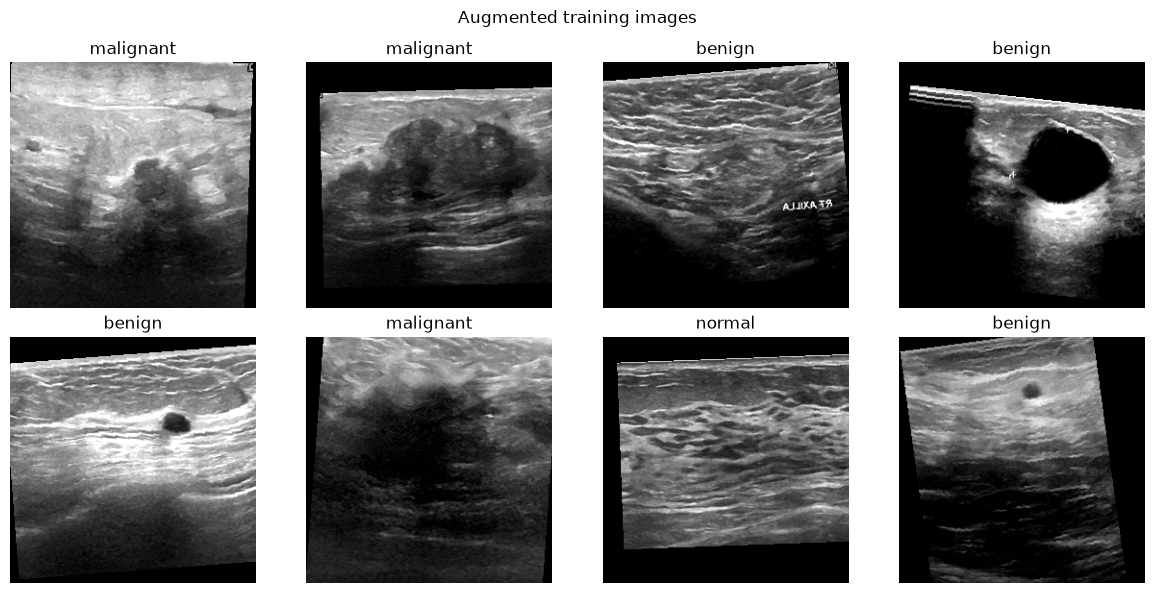

In [7]:
# Look at one batch of augmented training images
images, targets = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, target in zip(axes.flat, images, targets):
    ax.imshow((image[0] * IMAGENET_STD[0] + IMAGENET_MEAN[0]).numpy(), cmap='gray')   # undo normalisation to display
    ax.set_title(CLASSES[target])
    ax.axis('off')
plt.suptitle('Augmented training images')
plt.tight_layout()
plt.show()

## 5. Model, loss and optimizer

We take a ResNet18 already trained on ImageNet and replace its last layer (1000 ImageNet classes) with a new one that has 3 outputs.

Benign images outnumber normal ones by about 3 to 1, so the loss uses **class weights**: mistakes on rarer classes cost more.

In [8]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)   # pretrained on ImageNet
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))           # new last layer: 512 features -> 3 classes
model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/prajwalnerkar/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


In [9]:
counts = train_df['target'].value_counts().sort_index()                            # images per class (train)
class_weights = torch.tensor(len(train_df) / (len(CLASSES) * counts.values), dtype=torch.float32)
print('Class weights:', dict(zip(CLASSES, class_weights.numpy().round(2).tolist())))

loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

Class weights: {'normal': 2.069999933242798, 'benign': 0.6100000143051147, 'malignant': 1.1399999856948853}


## 6. Train

After every epoch we check the validation loss. Whenever it reaches a new best, the model is saved to `model.pt`. If it hasn't improved for `PATIENCE` epochs, training stops early (**early stopping**).

In [10]:
def run_epoch(loader, train):
    """One pass over the data. Updates the weights only when train=True. Returns (loss, accuracy)."""
    model.train(train)                                 # train mode or evaluation mode
    total_loss, correct = 0.0, 0

    for images, targets in loader:
        images, targets = images.to(device), targets.to(device)

        with torch.set_grad_enabled(train):            # only track gradients when training
            logits = model(images)
            loss = loss_fn(logits, targets)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * len(targets)
        correct += (logits.argmax(dim=1) == targets).sum().item()

    return total_loss / len(loader.dataset), correct / len(loader.dataset)

In [11]:
history = []
best_val_loss, best_epoch, epochs_without_improvement = float('inf'), 0, 0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)
    history.append({'epoch': epoch, 'train_loss': train_loss, 'train_acc': train_acc,
                    'val_loss': val_loss, 'val_acc': val_acc})
    print(f'Epoch {epoch:2d} | train loss {train_loss:.4f}  acc {train_acc:.3f} '
          f'| val loss {val_loss:.4f}  acc {val_acc:.3f}')

    if val_loss < best_val_loss:                         # new best: save this model
        best_val_loss, best_epoch, epochs_without_improvement = val_loss, epoch, 0
        torch.save(model.state_dict(), OUTPUT_DIR / 'model.pt')
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f'Stopping early: no improvement for {PATIENCE} epochs')
            break

print(f'Best model: epoch {best_epoch} (val loss {best_val_loss:.4f}), saved to {OUTPUT_DIR}/model.pt')

history = pd.DataFrame(history)
history.to_csv(OUTPUT_DIR / 'history.csv', index=False)

Epoch  1 | train loss 0.8738  acc 0.579 | val loss 0.7044  acc 0.692
Epoch  2 | train loss 0.5463  acc 0.748 | val loss 0.6541  acc 0.740
Epoch  3 | train loss 0.3934  acc 0.812 | val loss 0.4541  acc 0.827
Epoch  4 | train loss 0.2886  acc 0.878 | val loss 0.6202  acc 0.750
Epoch  5 | train loss 0.2381  acc 0.905 | val loss 0.3600  acc 0.875
Epoch  6 | train loss 0.2219  acc 0.899 | val loss 0.3738  acc 0.837
Epoch  7 | train loss 0.2064  acc 0.918 | val loss 0.3961  acc 0.827
Epoch  8 | train loss 0.1906  acc 0.913 | val loss 0.4412  acc 0.817
Epoch  9 | train loss 0.1272  acc 0.946 | val loss 0.4447  acc 0.798
Epoch 10 | train loss 0.1235  acc 0.965 | val loss 0.4686  acc 0.827
Epoch 11 | train loss 0.1292  acc 0.953 | val loss 0.3817  acc 0.837
Epoch 12 | train loss 0.1010  acc 0.969 | val loss 0.3796  acc 0.846
Stopping early: no improvement for 7 epochs
Best model: epoch 5 (val loss 0.3600), saved to outputs/classifier/model.pt


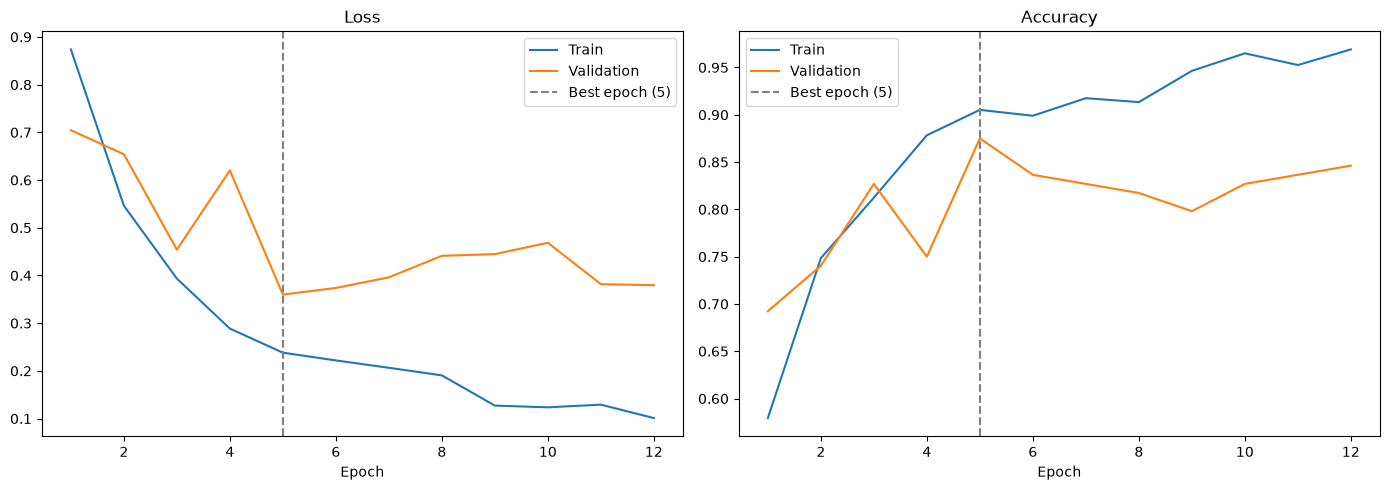

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, ['loss', 'acc']):
    ax.plot(history['epoch'], history[f'train_{metric}'], label='Train')
    ax.plot(history['epoch'], history[f'val_{metric}'], label='Validation')
    ax.axvline(best_epoch, color='grey', linestyle='--', label=f'Best epoch ({best_epoch})')
    ax.set_xlabel('Epoch')
    ax.set_title('Loss' if metric == 'loss' else 'Accuracy')
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Evaluate on the test set

We reload the **best** saved model (not the last epoch) and run it once on the test set, which it has never seen.

In [13]:
model.load_state_dict(torch.load(OUTPUT_DIR / 'model.pt', map_location=device))
model.eval()

all_probs = []
with torch.no_grad():
    for images, _ in test_loader:
        all_probs.append(torch.softmax(model(images.to(device)), dim=1).cpu())   # scores -> probabilities
probs = torch.cat(all_probs).numpy()          # one row per test image: [P(normal), P(benign), P(malignant)]

y_true = test_df['target'].values
y_pred = probs.argmax(axis=1)                 # most likely class

# Save every test prediction (used by the app to show results)
results = test_df[['image_path', 'label', 'has_markers']].copy()
for i, class_name in enumerate(CLASSES):
    results[f'prob_{class_name}'] = probs[:, i].round(4)
results['predicted'] = [CLASSES[i] for i in y_pred]
results['correct'] = results['predicted'] == results['label']
results.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

              precision    recall  f1-score   support

      normal      0.750     0.882     0.811        17
      benign      0.862     0.877     0.870        57
   malignant      0.885     0.767     0.821        30

    accuracy                          0.846       104
   macro avg      0.832     0.842     0.834       104
weighted avg      0.850     0.846     0.846       104



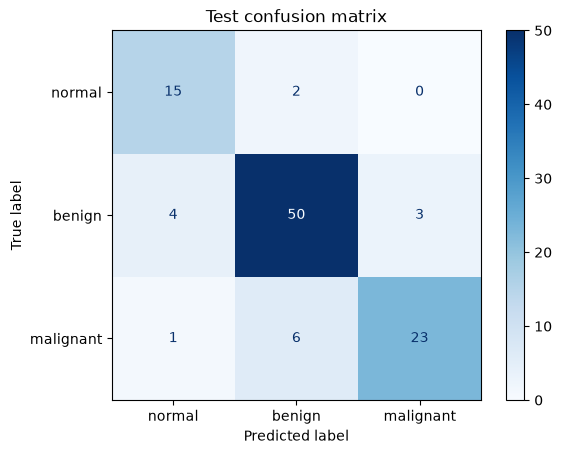

In [14]:
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASSES).plot(cmap='Blues')
plt.title('Test confusion matrix')
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

### Our two questions

1. **Tumour or not:** P(tumour) = P(benign) + P(malignant).
   - **Sensitivity:** % of tumours found.
   - **Specificity:** % of normal scans correctly called normal.
2. **Malignant or not:** **malignant recall** = % of cancers caught. This is the most important number, because missing a cancer is the worst mistake.

**ROC-AUC** measures how well the probabilities separate the classes, from 0.5 (random guessing) to 1.0 (perfect).

In [15]:
# 1. Tumour vs normal
is_tumour = y_true != 0
p_tumour = probs[:, 1] + probs[:, 2]
pred_tumour = p_tumour >= 0.5

# 2. Malignant vs the rest
is_malignant = y_true == 2
p_malignant = probs[:, 2]

metrics = {
    'accuracy': float((y_pred == y_true).mean()),
    'tumour_sensitivity': float((pred_tumour & is_tumour).sum() / is_tumour.sum()),
    'tumour_specificity': float((~pred_tumour & ~is_tumour).sum() / (~is_tumour).sum()),
    'tumour_roc_auc': float(roc_auc_score(is_tumour, p_tumour)),
    'malignant_recall': float(((y_pred == 2) & is_malignant).sum() / is_malignant.sum()),
    'malignant_precision': float(((y_pred == 2) & is_malignant).sum() / max((y_pred == 2).sum(), 1)),
    'malignant_roc_auc': float(roc_auc_score(is_malignant, p_malignant)),
    'roc_auc_3_class': float(roc_auc_score(y_true, probs, multi_class='ovr')),
    'test_images': int(len(y_true)),
}

for name, value in metrics.items():
    print(f'{name:22s} {value:.3f}' if isinstance(value, float) else f'{name:22s} {value}')

accuracy               0.846
tumour_sensitivity     0.954
tumour_specificity     0.824
tumour_roc_auc         0.975
malignant_recall       0.767
malignant_precision    0.885
malignant_roc_auc      0.950
roc_auc_3_class        0.950
test_images            104


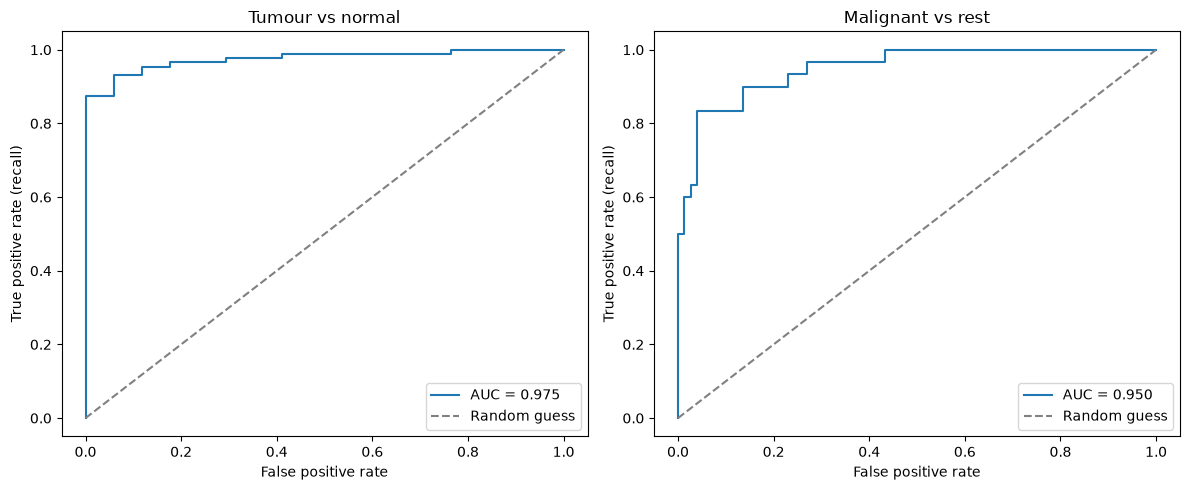

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (title, truth, score, auc) in zip(axes, [
    ('Tumour vs normal', is_tumour, p_tumour, metrics['tumour_roc_auc']),
    ('Malignant vs rest', is_malignant, p_malignant, metrics['malignant_roc_auc']),
]):
    false_pos_rate, true_pos_rate, _ = roc_curve(truth, score)
    ax.plot(false_pos_rate, true_pos_rate, label=f'AUC = {auc:.3f}')
    ax.plot([0, 1], [0, 1], color='grey', linestyle='--', label='Random guess')
    ax.set_xlabel('False positive rate')
    ax.set_ylabel('True positive rate (recall)')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'roc_curves.png', dpi=120, bbox_inches='tight')
plt.show()

### Shortcut check: images with vs without markers

If accuracy is much higher on images with markers, the model may be using the markers instead of the tissue.

In [17]:
marker_check = results.groupby('has_markers')['correct'].agg(accuracy='mean', images='count')
metrics['accuracy_with_markers'] = float(marker_check['accuracy'].get(True, float('nan')))
metrics['accuracy_without_markers'] = float(marker_check['accuracy'].get(False, float('nan')))

(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2))   # save all test results
marker_check.round(3)

,accuracy,images
has_markers,,
False,0.949,39
True,0.785,65


## 8. Grad-CAM: where is the model looking?

Grad-CAM colours the parts of the image that pushed the model towards its prediction (red = most important). The **green outline** is the real lesion from the mask. A good model should light up inside or around the green outline, not on markers or empty areas.

In [18]:
def grad_cam(model, image_tensor, class_index):
    """Heatmap (IMAGE_SIZE x IMAGE_SIZE, 0 to 1) of the regions that support class_index."""
    saved = {}
    hook = model.layer4.register_forward_hook(lambda module, inp, out: saved.update(features=out))   # last conv block
    logits = model(image_tensor.unsqueeze(0).to(device))
    hook.remove()

    features = saved['features']                                          # shape (1, 512, 8, 8)
    gradients = torch.autograd.grad(logits[0, class_index], features)[0]  # how each feature affects the score
    weights = gradients.mean(dim=(2, 3), keepdim=True)                    # importance of each of the 512 channels
    cam = F.relu((weights * features).sum(dim=1, keepdim=True))           # weighted sum, keep positive evidence
    cam = F.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode='bilinear', align_corners=False)
    cam = cam.squeeze().detach().cpu().numpy()
    return cam / (cam.max() + 1e-8)                                       # scale to 0..1


def load_padded_mask(mask_paths):
    """Merge an image's masks and pad/resize them exactly like the image."""
    masks = [np.array(Image.open(DATA_DIR / p).convert('L')) > 127 for p in mask_paths.split(';')]
    merged = Image.fromarray(np.any(masks, axis=0).astype(np.uint8) * 255)
    return np.array(pad_to_square(merged)) > 127

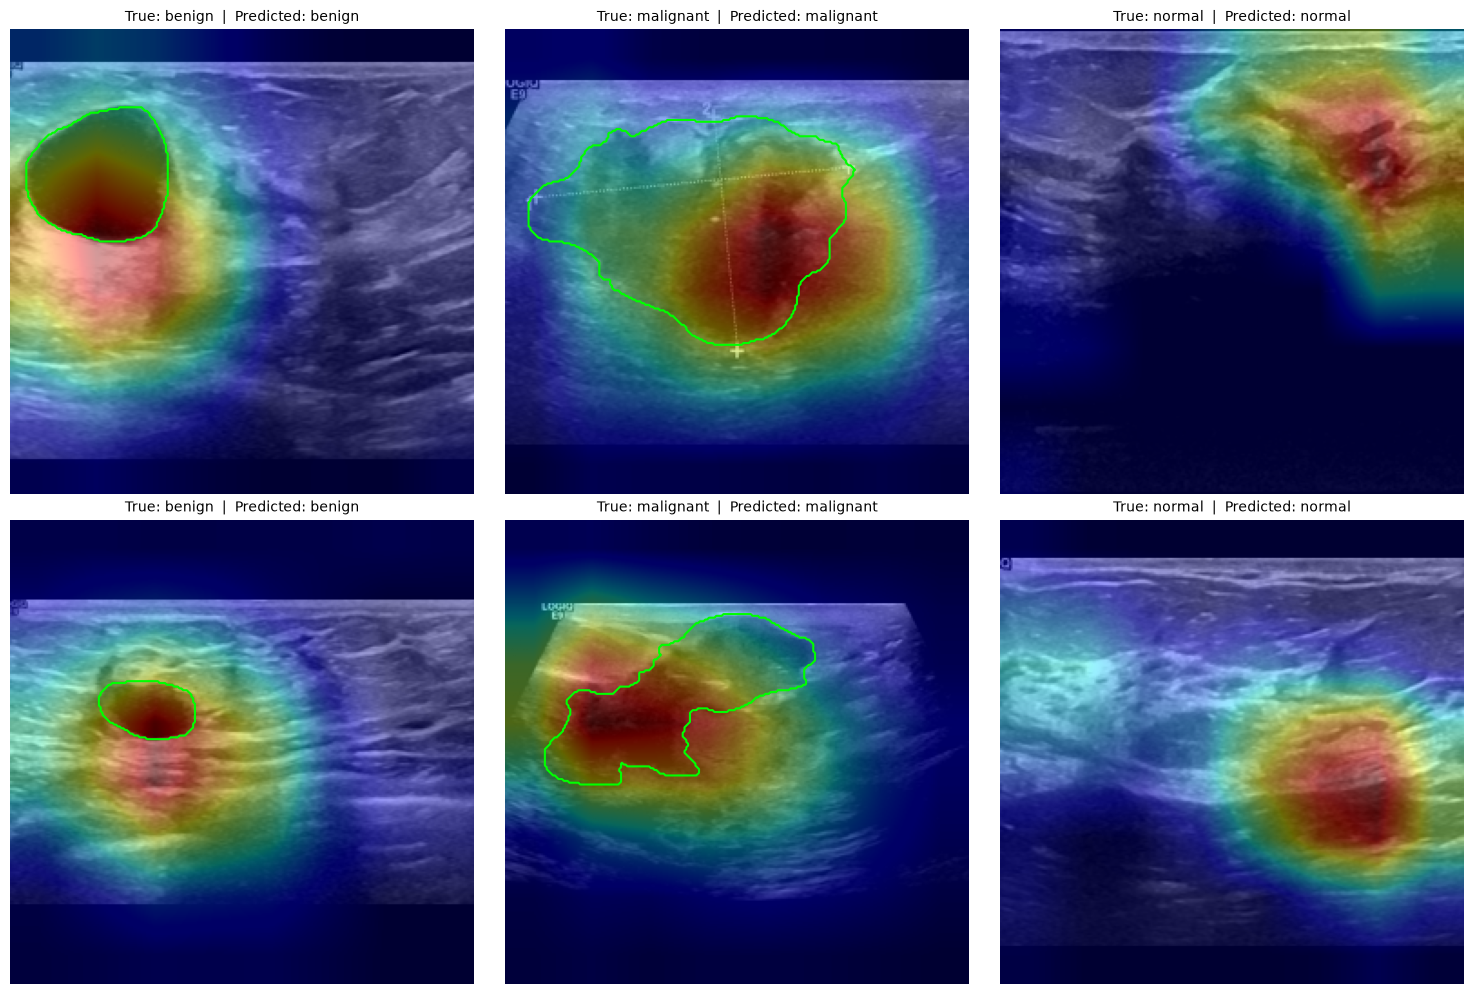

In [19]:
examples = test_df.groupby('label', group_keys=False).sample(2, random_state=RANDOM_STATE)   # 2 per class

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, row in zip(axes.T.flat, examples.itertuples()):
    image = pad_to_square(Image.open(DATA_DIR / row.image_path))
    tensor = eval_transform(image)

    with torch.no_grad():
        prediction = model(tensor.unsqueeze(0).to(device)).argmax(dim=1).item()
    cam = grad_cam(model, tensor, prediction)

    ax.imshow(image, cmap='gray')
    ax.imshow(cam, cmap='jet', alpha=0.4)                                         # Grad-CAM heatmap
    mask = load_padded_mask(row.mask_paths)
    if mask.any():
        ax.contour(mask, levels=[0.5], colors='lime', linewidths=1.5)            # real lesion outline
    ax.set_title(f'True: {row.label}  |  Predicted: {CLASSES[prediction]}', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'gradcam_examples.png', dpi=120, bbox_inches='tight')
plt.show()

## 9. Save the config

The app needs to rebuild exactly the same model and preprocess uploaded images exactly the same way. Everything it needs is stored here.

In [20]:
config = {
    'model_name': 'ResNet18 classifier',
    'architecture': 'resnet18',
    'classes': CLASSES,
    'image_size': IMAGE_SIZE,
    'preprocessing': 'grayscale -> pad to square with black -> resize -> 3 channels -> ImageNet normalisation',
    'normalize_mean': IMAGENET_MEAN,
    'normalize_std': IMAGENET_STD,
    'gradcam_layer': 'layer4',
    'best_epoch': int(best_epoch),
    'epochs_trained': int(len(history)),
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'class_weights': class_weights.numpy().round(4).tolist(),
    'images': {'train': len(train_df), 'val': len(val_df), 'test': len(test_df)},
    'trained_on': datetime.now().strftime('%Y-%m-%d %H:%M'),
}

(OUTPUT_DIR / 'config.json').write_text(json.dumps(config, indent=2))
print('Saved files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f'  {path.name:24s} {path.stat().st_size / 1024:8.1f} KB')

Saved files:
  config.json                   0.7 KB
  confusion_matrix.png         23.3 KB
  gradcam_examples.png       1545.9 KB
  history.csv                   0.9 KB
  metrics.json                  0.4 KB
  model.pt                  43733.4 KB
  roc_curves.png               40.2 KB
  test_predictions.csv          7.4 KB
  training_curves.png          80.6 KB


## 10. Check: reload and predict, the way the app will

This rebuilds the model from the saved files alone, without using anything trained above, and predicts one test image. If it works here, the app can use the same two functions.

In [21]:
def load_classifier(folder):
    """Rebuild the trained classifier from model.pt and config.json."""
    config = json.loads((folder / 'config.json').read_text())
    net = models.resnet18(weights=None)                                  # same architecture, no download
    net.fc = nn.Linear(net.fc.in_features, len(config['classes']))
    net.load_state_dict(torch.load(folder / 'model.pt', map_location='cpu'))
    net.eval()
    return net, config


def predict(net, config, image):
    """Class probabilities for one PIL image, e.g. an image uploaded in the app."""
    size = config['image_size']
    preprocess = transforms.Compose([
        transforms.Grayscale(num_output_channels=3),
        transforms.ToTensor(),
        transforms.Normalize(config['normalize_mean'], config['normalize_std']),
    ])
    tensor = preprocess(ImageOps.pad(image.convert('L'), (size, size), color=0)).unsqueeze(0)
    with torch.no_grad():
        probabilities = torch.softmax(net(tensor), dim=1)[0].numpy()
    return dict(zip(config['classes'], probabilities.round(4).tolist()))


net, saved_config = load_classifier(OUTPUT_DIR)
sample = test_df.iloc[0]
print('Image:     ', sample['image_path'])
print('True label:', sample['label'])
print('Predicted: ', predict(net, saved_config, Image.open(DATA_DIR / sample['image_path'])))

Image:      normal/normal (103).png
True label: normal
Predicted:  {'normal': 0.9926000237464905, 'benign': 0.007000000216066837, 'malignant': 0.00039999998989515007}
